In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, precision_score, recall_score,
                             f1_score, roc_curve)

FIG = Path("../reports/figures")
df = pd.read_csv("../data/processed/loans_clean.csv")
y = df["default"]

# installment is left out: it is 0.95 correlated with loan_amnt
num_A = ["loan_amnt", "term", "annual_inc", "dti", "fico_avg", "delinq_2yrs",
         "pub_rec", "open_acc", "total_acc", "revol_bal", "revol_util",
         "emp_length", "emp_length_missing", "loan_to_income"]
cat_A = ["home_ownership", "verification_status", "purpose"]
num_B = num_A + ["int_rate"]
cat_B = cat_A + ["grade"]

train_idx, test_idx = train_test_split(df.index, test_size=0.2,
                                       stratify=y, random_state=42)
print(len(train_idx), "training loans,", len(test_idx), "test loans")

200000 training loans, 50000 test loans


In [2]:
def build(num, cat):
    pre = ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    return Pipeline([("prep", pre), ("clf", LogisticRegression(max_iter=1000))])

model_A = build(num_A, cat_A).fit(df.loc[train_idx, num_A + cat_A], y[train_idx])
model_B = build(num_B, cat_B).fit(df.loc[train_idx, num_B + cat_B], y[train_idx])
print("Both models trained")

Both models trained


In [3]:
yt = y[test_idx]
results, probs = [], {}
for name, model, cols in [("A: applicant info only", model_A, num_A + cat_A),
                          ("B: plus interest rate and grade", model_B, num_B + cat_B)]:
    p = model.predict_proba(df.loc[test_idx, cols])[:, 1]
    pred = (p >= 0.20).astype(int)
    probs[name] = p
    results.append({"model": name,
                    "ROC-AUC": roc_auc_score(yt, p),
                    "precision": precision_score(yt, pred),
                    "recall": recall_score(yt, pred),
                    "F1": f1_score(yt, pred)})
pd.DataFrame(results).round(3)

,model,ROC-AUC,precision,recall,F1
0,A: applicant info only,0.694,0.308,0.626,0.413
1,B: plus interest rate and grade,0.712,0.315,0.668,0.428


In [4]:
names = model_A.named_steps["prep"].get_feature_names_out()
coefs = model_A.named_steps["clf"].coef_[0]
imp = pd.Series(coefs, index=names).sort_values(key=abs, ascending=False)
print(imp.head(12).round(3))

cat__purpose_small_business                 0.507
cat__home_ownership_MORTGAGE               -0.442
cat__purpose_credit_card                   -0.429
cat__verification_status_Not Verified      -0.393
num__term                                   0.380
cat__purpose_car                           -0.376
num__fico_avg                              -0.374
cat__purpose_debt_consolidation            -0.273
cat__home_ownership_OWN                    -0.222
num__dti                                    0.205
num__open_acc                               0.196
cat__verification_status_Source Verified   -0.189
dtype: float64


In [5]:
p = probs["A: applicant info only"]
lo, hi = np.quantile(p, [0.40, 0.80])

out = df.loc[test_idx, ["loan_amnt", "purpose", "addr_state", "grade", "default"]].copy()
out["default_probability"] = p
out["risk_bucket"] = pd.cut(p, [-np.inf, lo, hi, np.inf],
                            labels=["Low", "Medium", "High"])

print(out.groupby("risk_bucket", observed=True)["default"]
         .agg(loans="count", actual_default_rate="mean").round(3))
out.to_csv("../data/processed/risk_predictions.csv", index=False)

             loans  actual_default_rate
risk_bucket                            
Low          20000                0.098
Medium       20000                0.211
High         10000                0.375


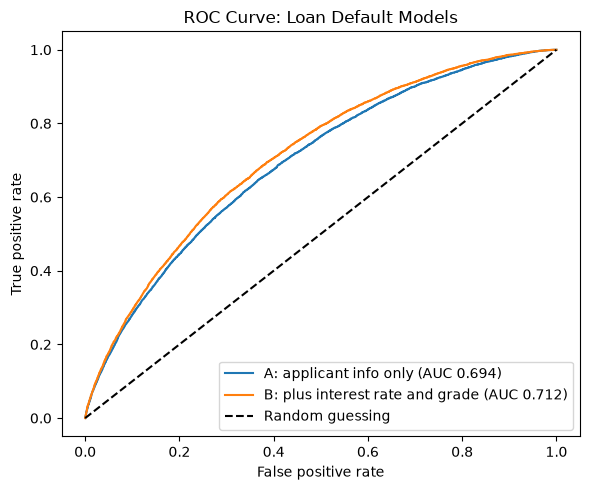

['../data/processed/logreg_model_A.joblib']

In [6]:
plt.figure(figsize=(6, 5))
for name, pr in probs.items():
    fpr, tpr, _ = roc_curve(yt, pr)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(yt, pr):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Curve: Loan Default Models")
plt.legend()
plt.tight_layout()
plt.savefig(FIG / "roc_curve.png", dpi=200)
plt.show()

joblib.dump(model_A, "../data/processed/logreg_model_A.joblib")

In [7]:
full = df[["loan_amnt", "term", "purpose", "addr_state", "grade",
           "income_bracket", "fico_avg", "issue_year", "default"]].copy()
full["fico_band"] = pd.cut(full["fico_avg"], [0, 680, 700, 720, 740, np.inf],
                           right=False,
                           labels=["1. Below 680", "2. 680-699", "3. 700-719",
                                   "4. 720-739", "5. 740+"]).astype(str)
full["default_probability"] = model_A.predict_proba(df[num_A + cat_A])[:, 1]
full["risk_bucket"] = pd.cut(full["default_probability"], [-np.inf, lo, hi, np.inf],
                             labels=["Low", "Medium", "High"]).astype(str)
full["data_split"] = np.where(df.index.isin(test_idx), "Test", "Train")

full.to_csv("../data/processed/dashboard_data.csv", index=False)
print(full.shape)
print(full.groupby("risk_bucket")["default"].agg(["count", "mean"]).round(3))

(250000, 13)
             count   mean
risk_bucket              
High         50423  0.376
Low          99634  0.099
Medium       99943  0.209


In [8]:
full["income_order"] = full["income_bracket"].map(
    {"<30k": 1, "30-60k": 2, "60-90k": 3, "90-120k": 4, "120k+": 5})
full["risk_order"] = full["risk_bucket"].map({"Low": 1, "Medium": 2, "High": 3})

full.to_csv("../data/processed/dashboard_data.csv", index=False)
print(full.shape)
print(full[["income_bracket", "income_order", "risk_bucket", "risk_order"]]
      .drop_duplicates().sort_values(["income_order", "risk_order"]).head(15))

(250000, 15)
    income_bracket  income_order risk_bucket  risk_order
127           <30k             1         Low           1
1             <30k             1      Medium           2
0             <30k             1        High           3
20          30-60k             2         Low           1
2           30-60k             2      Medium           2
9           30-60k             2        High           3
3           60-90k             3         Low           1
29          60-90k             3      Medium           2
41          60-90k             3        High           3
6          90-120k             4         Low           1
5          90-120k             4      Medium           2
18         90-120k             4        High           3
14           120k+             5         Low           1
10           120k+             5      Medium           2
383          120k+             5        High           3
